In [2]:
import pandas as pd

df = pd.read_csv('D:\\Semester 5\\ML\\244107020017_Machine_Learning\\JS09\\dataset\\spam.csv', encoding='latin-1')
df.head()


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
from sklearn.model_selection import train_test_split

# Ambil kolom label dan pesan
df = df[['v1', 'v2']].dropna()
df.columns = ['label', 'pesan']

print(df.head())
print(df['label'].value_counts())

X = df['pesan']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


  label                                              pesan
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64


Evaluasi CountVectorizer
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115

Accuracy : 0.9838565022421525
Precision: 0.958041958041958
Recall   : 0.9194630872483222
F1-Score : 0.9383561643835616


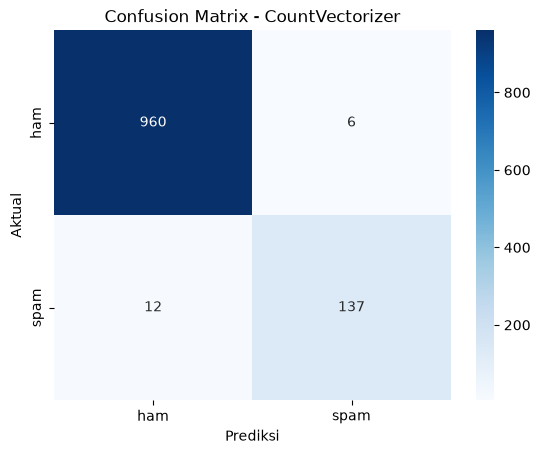

In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

count_vectorizer = CountVectorizer(stop_words='english')

X_train_count = count_vectorizer.fit_transform(X_train)
X_test_count = count_vectorizer.transform(X_test)

model_count = MultinomialNB()
model_count.fit(X_train_count, y_train)

y_pred_count = model_count.predict(X_test_count)

print("Evaluasi CountVectorizer")
print(classification_report(y_test, y_pred_count))

print("Accuracy :", accuracy_score(y_test, y_pred_count))
print("Precision:", precision_score(
    y_test, y_pred_count, pos_label='spam'
))
print("Recall   :", recall_score(
    y_test, y_pred_count, pos_label='spam'
))
print("F1-Score :", f1_score(
    y_test, y_pred_count, pos_label='spam'
))

cm_count = confusion_matrix(
    y_test, y_pred_count, labels=['ham', 'spam']
)

sns.heatmap(
    cm_count, annot=True, fmt='d', cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - CountVectorizer')
plt.show()


Evaluasi TF-IDF
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115

Accuracy : 0.968609865470852
Precision: 1.0
Recall   : 0.7651006711409396
F1-Score : 0.8669201520912547


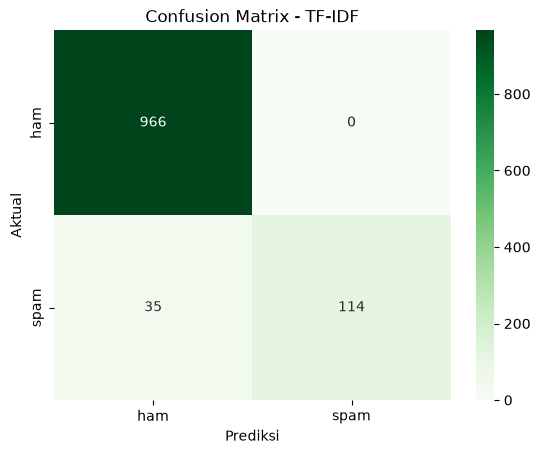

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

model_tfidf = MultinomialNB()
model_tfidf.fit(X_train_tfidf, y_train)

y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

print("Evaluasi TF-IDF")
print(classification_report(y_test, y_pred_tfidf))

print("Accuracy :", accuracy_score(y_test, y_pred_tfidf))
print("Precision:", precision_score(
    y_test, y_pred_tfidf, pos_label='spam'
))
print("Recall   :", recall_score(
    y_test, y_pred_tfidf, pos_label='spam'
))
print("F1-Score :", f1_score(
    y_test, y_pred_tfidf, pos_label='spam'
))

cm_tfidf = confusion_matrix(
    y_test, y_pred_tfidf, labels=['ham', 'spam']
)

sns.heatmap(
    cm_tfidf, annot=True, fmt='d', cmap='Greens',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - TF-IDF')
plt.show()


,Metode,Accuracy,Precision Spam,Recall Spam,F1-Score Spam
0,CountVectorizer,0.9839,0.958,0.9195,0.9384
1,TF-IDF,0.9686,1.000,0.7651,0.8669


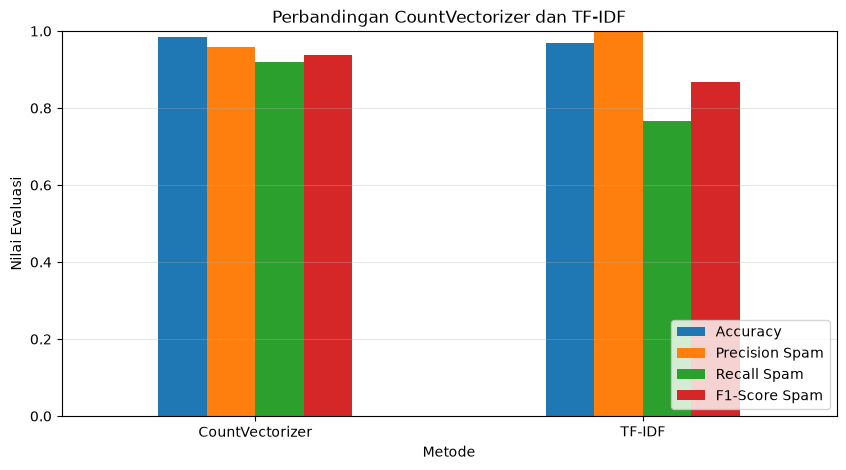

In [6]:
hasil = pd.DataFrame({
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_count),
        accuracy_score(y_test, y_pred_tfidf)
    ],
    'Precision Spam': [
        precision_score(y_test, y_pred_count, pos_label='spam'),
        precision_score(y_test, y_pred_tfidf, pos_label='spam')
    ],
    'Recall Spam': [
        recall_score(y_test, y_pred_count, pos_label='spam'),
        recall_score(y_test, y_pred_tfidf, pos_label='spam')
    ],
    'F1-Score Spam': [
        f1_score(y_test, y_pred_count, pos_label='spam'),
        f1_score(y_test, y_pred_tfidf, pos_label='spam')
    ]
})

display(hasil.round(4))

# Visualisasi perbandingan metrik
hasil_plot = hasil.set_index('Metode')
hasil_plot.plot(kind='bar', figsize=(10, 5), ylim=(0, 1))

plt.title('Perbandingan CountVectorizer dan TF-IDF')
plt.ylabel('Nilai Evaluasi')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right')
plt.show()


kesimpulan : CountVectorizer merupakan fitur terbaik, berdasarkan accuracy, recall, dan F1-score. Sementara itu, TF-IDF lebih unggul dalam ketepatan Precision spam.